### <font color = "gold"> Import les librairies requises

In [189]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [190]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [191]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [192]:
# Importer les données
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/wheat_seeds_dataset.csv")

**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

In [193]:
# Afficher les données
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [194]:
# Dimension des données
df.shape

(199, 7)

In [195]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [196]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [197]:
# Renommer les index
df.index = ["Graine" + str(i +1) for i in range(len(df))]
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [198]:
import joblib as jb
jb.dump(df.columns.tolist(),"/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/colonnes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/colonnes.joblib']

In [199]:
# Matrice des données
df.corr()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
area A,1.000000,0.994437,0.609887,0.951126,0.970980,-0.222820,0.862727
perimeter,0.994437,1.000000,0.531841,0.972944,0.945496,-0.211034,0.889543
compactness,0.609887,0.531841,1.000000,0.374011,0.762167,-0.329400,0.227016
length of kernel,0.951126,0.972944,0.374011,1.000000,0.862680,-0.169704,0.932124
width of kernel,0.970980,0.945496,0.762167,0.862680,1.000000,-0.253122,0.748228
asymmetry coefficient,-0.222820,-0.211034,-0.329400,-0.169704,-0.253122,1.000000,-0.003349
length of kernel groove,0.862727,0.889543,0.227016,0.932124,0.748228,-0.003349,1.000000


In [200]:
# matrice des donnees
x = df.values
x[:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

In [201]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[0.66271789, 0.64447795, 0.03782617, 0.25027806, 0.14383497,
        0.09645455, 0.22669642],
       [0.66410726, 0.65027169, 0.03932425, 0.24787982, 0.14875467,
        0.04543422, 0.22119056],
       [0.65688362, 0.64769001, 0.0416011 , 0.24321702, 0.15339543,
        0.1240678 , 0.2217959 ],
       [0.64909686, 0.65378687, 0.04199901, 0.24969593, 0.15847531,
        0.10594724, 0.2253548 ],
       [0.68244585, 0.63382053, 0.03819836, 0.23923659, 0.15061166,
        0.05729332, 0.21881396]])

#### <font color = "gold"> Appliquer une ACP

In [202]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)

# Matrice des 2 composantes
features_pca = pca.fit_transform(x)


# Dataframe
df_pca = pd.DataFrame(features_pca, columns=["PCA1", "PCA2"])

In [203]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(98.55)

### <font color = "gold"> Kmeans

In [204]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

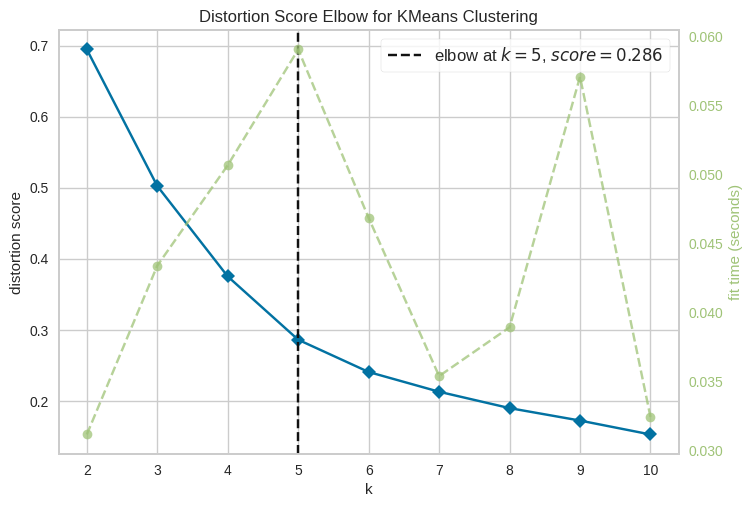

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [205]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [206]:
# Initier le modèle
kmeans_model = KMeans(n_clusters=4, init="random", max_iter=500 )
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color = "bisque"> Prédiction la partition

In [207]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([2, 2, 0, 0, 2, 2, 0, 2, 2, 1, 2, 0, 0, 0, 1, 3, 2, 2, 0, 0, 0, 2,
       0, 2, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 2, 0, 3, 0, 0, 0, 1, 0, 2,
       2, 0, 0, 2, 0, 1, 0, 0, 2, 2, 0, 2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 0,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 1, 1, 2, 2,
       2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 1, 1,
       2, 1, 2, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 2, 1, 2, 2, 1, 1, 1, 1, 2,
       2, 1, 3, 3, 3, 3, 3, 3, 0, 3, 0, 3, 3, 3, 3, 0, 3, 3, 0, 3, 3, 3,
       0, 3, 3, 3, 3, 0, 3, 0, 3, 3, 3, 3, 3, 3, 3, 3, 0, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 0, 3, 3, 3, 3, 3, 0, 0, 3, 3, 0, 0, 3, 3, 0,
       3], dtype=int32)

In [208]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
print(val)

2    56
3    53
0    49
1    41
Name: count, dtype: int64


In [209]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val.index, y = val.values, color =val.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [210]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2', color = kmeans_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [211]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x,kmeans_partition)
print(sil_kmeans)

0.3837887447559465


In [212]:
# Les graines de chaque classes
clusters_names = []
for i in range(4):
  clusters_names.append(list(df.index[kmeans_partition==i]))

In [213]:
# Afficher les graines de la classe 0
print(clusters_names[0])

['Graine3', 'Graine4', 'Graine7', 'Graine12', 'Graine13', 'Graine14', 'Graine19', 'Graine20', 'Graine21', 'Graine23', 'Graine26', 'Graine27', 'Graine28', 'Graine29', 'Graine31', 'Graine32', 'Graine33', 'Graine37', 'Graine39', 'Graine40', 'Graine41', 'Graine43', 'Graine46', 'Graine47', 'Graine49', 'Graine51', 'Graine52', 'Graine55', 'Graine58', 'Graine59', 'Graine60', 'Graine61', 'Graine63', 'Graine65', 'Graine66', 'Graine141', 'Graine143', 'Graine148', 'Graine151', 'Graine155', 'Graine160', 'Graine162', 'Graine171', 'Graine184', 'Graine190', 'Graine191', 'Graine194', 'Graine195', 'Graine198']


### <font color = "gold"> CAH

In [214]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

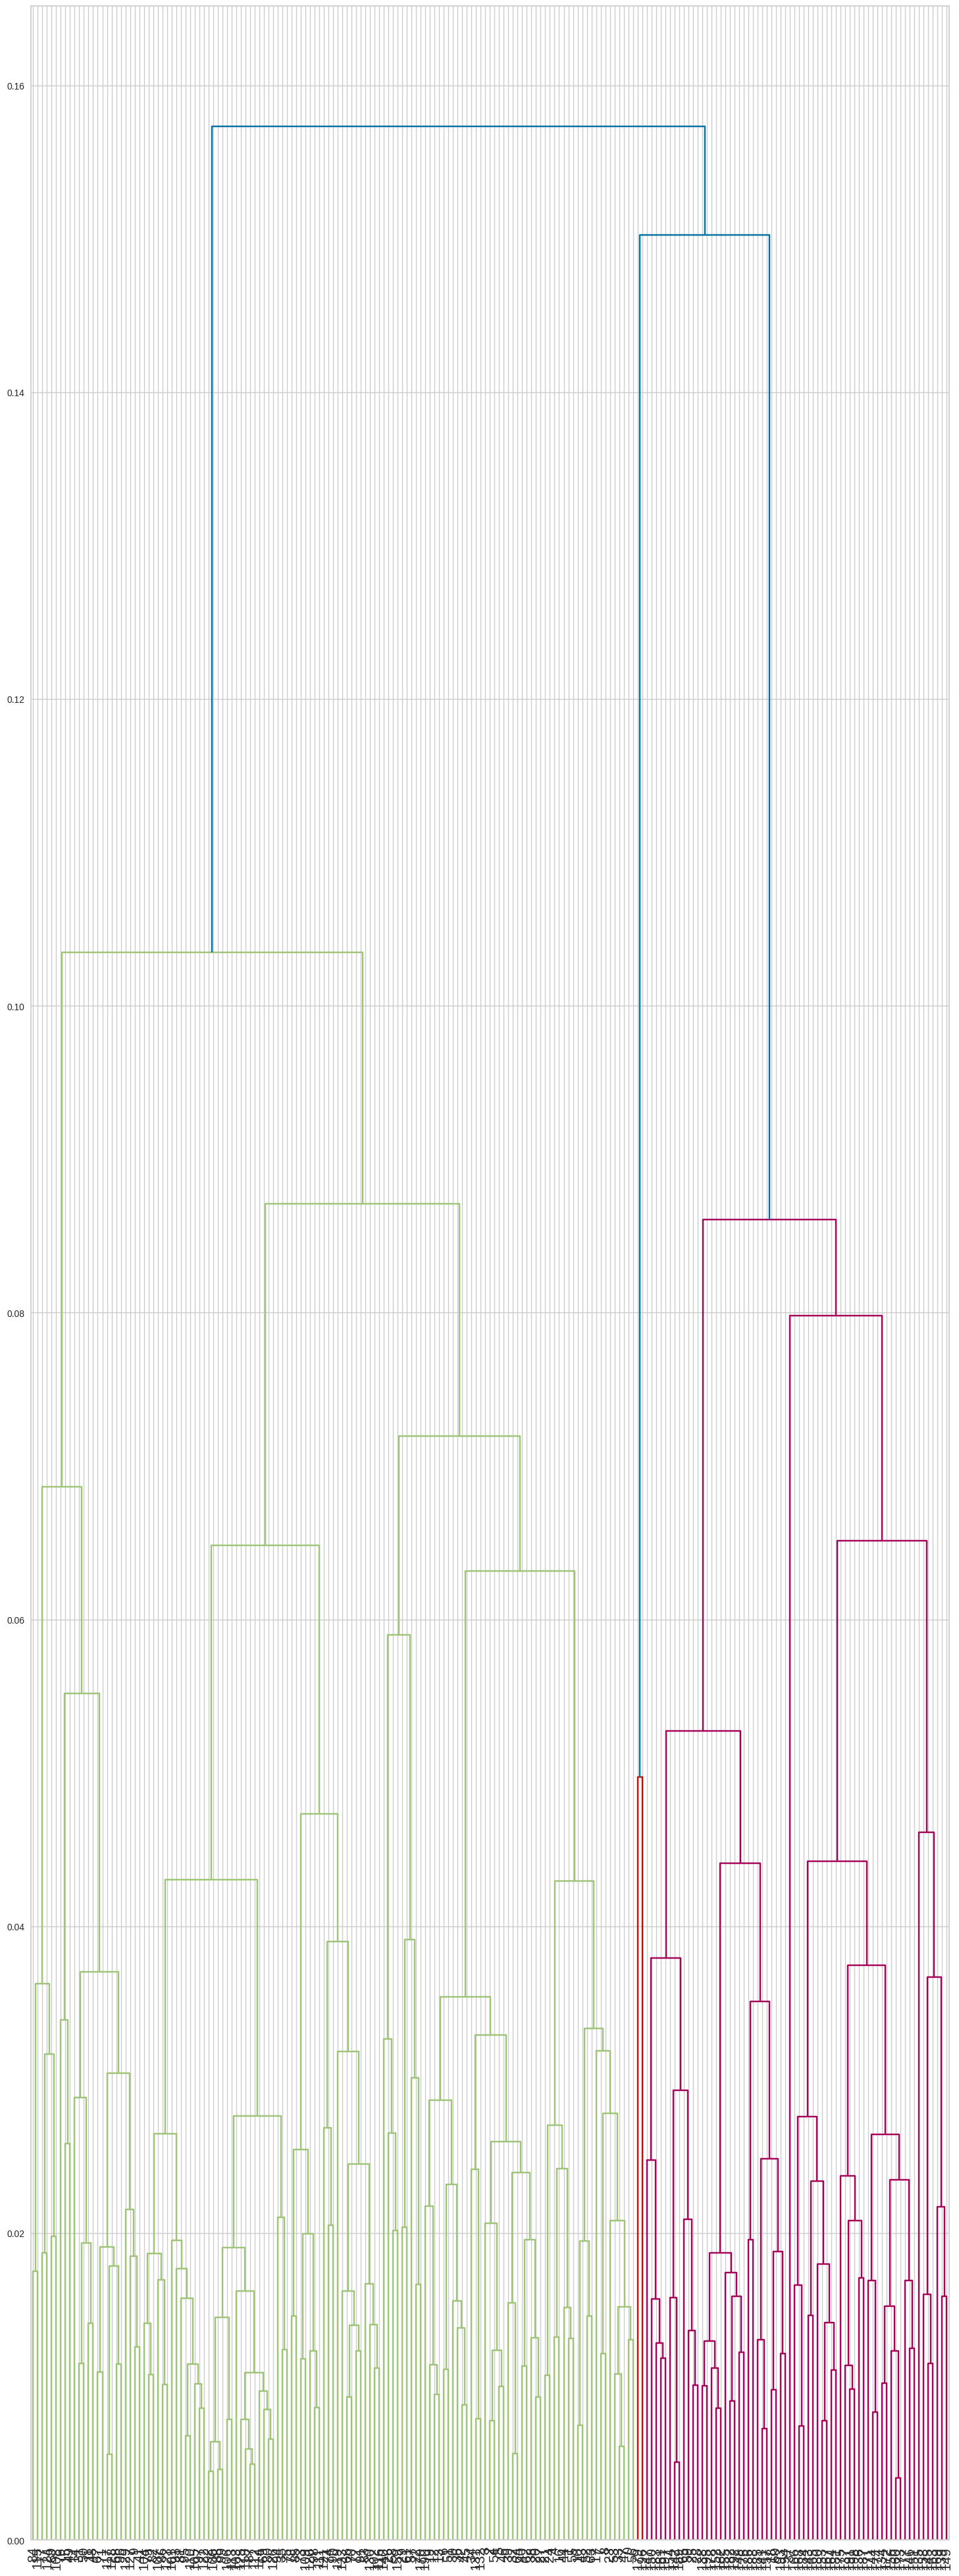

In [215]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [216]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=2,linkage="average")
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average')

In [217]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0])

In [218]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
1,131
0,68


In [219]:
# Diagramme en barre des nombres d'observations
fig = px.bar(x = val1.index, y = val1.values, color =val1.index.astype(str))
fig.show()

In [220]:
# Visualiser les classes
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2', color = cah_partition.astype(str))
fig.show()

In [221]:
# Silhouette score
sil_cah = silhouette_score(x,cah_partition)
print(f"La silhouette: {sil_cah} ")

La silhouette: 0.48377196978779624 


In [222]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [223]:
# les graines de chaque classe
cluster_names = []
for i in range(2):
 cluster_names.append(list(df.index[cah_partition== i]))

In [224]:
# Les graines de la classe 0
print(cluster_names[1])

['Graine1', 'Graine2', 'Graine3', 'Graine4', 'Graine5', 'Graine6', 'Graine7', 'Graine8', 'Graine9', 'Graine10', 'Graine11', 'Graine12', 'Graine13', 'Graine14', 'Graine15', 'Graine16', 'Graine17', 'Graine18', 'Graine20', 'Graine21', 'Graine22', 'Graine23', 'Graine24', 'Graine25', 'Graine27', 'Graine28', 'Graine30', 'Graine31', 'Graine32', 'Graine33', 'Graine34', 'Graine35', 'Graine36', 'Graine37', 'Graine39', 'Graine40', 'Graine41', 'Graine42', 'Graine43', 'Graine44', 'Graine45', 'Graine46', 'Graine47', 'Graine48', 'Graine49', 'Graine50', 'Graine51', 'Graine52', 'Graine53', 'Graine54', 'Graine55', 'Graine56', 'Graine57', 'Graine58', 'Graine59', 'Graine62', 'Graine63', 'Graine64', 'Graine65', 'Graine67', 'Graine68', 'Graine69', 'Graine70', 'Graine71', 'Graine72', 'Graine73', 'Graine74', 'Graine75', 'Graine76', 'Graine77', 'Graine78', 'Graine79', 'Graine80', 'Graine81', 'Graine82', 'Graine83', 'Graine84', 'Graine85', 'Graine86', 'Graine87', 'Graine88', 'Graine89', 'Graine90', 'Graine91', 

In [225]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau):
    obs = normalize(np.array(nouveau, dtype=float).reshape(1, -1))
    distances = cdist(obs, centroides)
    return classes[distances.argmin()]

In [226]:
jb.dump(centroides,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/centroides.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/centroides.joblib']

In [227]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0].values))
print("Classe réelle de la CAH:", cah_partition[0])

Classe prédite  : 1
Classe réelle de la CAH: 1


In [228]:
# Profil moyen de chaque classe
profil = df.groupby(cah_partition).mean().round(2)
profil

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,11.99,13.31,0.85,5.25,2.87,4.85,5.11
1,16.44,15.27,0.88,5.85,3.47,3.10,5.58


In [229]:
# Noms des classes
noms_classes = {
    0: "Petites graines",
    1: "Grandes graines"
}

In [230]:
jb.dump(noms_classes,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/noms_classes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/wheat_seeds/noms_classes.joblib']